In [115]:
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import scorecardpy as sc
from sklearn.model_selection import train_test_split



In [168]:
# Since you are in notebooks/, go up one level to find data/
data_path = Path("../data/credit_score.csv")
df = pd.read_csv(data_path)

print(df)
df.head(2)

        CUST_ID  INCOME  SAVINGS     DEBT  R_SAVINGS_INCOME  R_DEBT_INCOME  \
0    C02COQEVYU   33269        0   532304            0.0000        16.0000   
1    C02OZKC0ZF   77158    91187   315648            1.1818         4.0909   
2    C03FHP2D0A   30917    21642   534864            0.7000        17.3000   
3    C03PVPPHOY   80657    64526   629125            0.8000         7.8000   
4    C04J69MUX0  149971  1172498  2399531            7.8182        16.0000   
..          ...     ...      ...      ...               ...            ...   
995  CZQHJC9HDH  328892  1465066  5501471            4.4546        16.7273   
996  CZRA4MLB0P   81404    88805   680837            1.0909         8.3637   
997  CZSOD1KVFX       0    42428    30760            3.2379         8.1889   
998  CZWC76UAUT   36011     8002   604181            0.2222        16.7777   
999  CZZV5B3SAL   44266   309859    44266            6.9999         1.0000   

     R_DEBT_SAVINGS  T_CLOTHING_12  T_CLOTHING_6  R_CLOTHING  .

,CUST_ID,INCOME,SAVINGS,DEBT,R_SAVINGS_INCOME,R_DEBT_INCOME,R_DEBT_SAVINGS,T_CLOTHING_12,T_CLOTHING_6,R_CLOTHING,...,R_EXPENDITURE_SAVINGS,R_EXPENDITURE_DEBT,CAT_GAMBLING,CAT_DEBT,CAT_CREDIT_CARD,CAT_MORTGAGE,CAT_SAVINGS_ACCOUNT,CAT_DEPENDENTS,CREDIT_SCORE,DEFAULT
0,C02COQEVYU,33269,0,532304,0.0000,16.0000,1.2000,1889,945,0.5003,...,0.0000,0.0625,High,1,0,0,0,0,444,1
1,C02OZKC0ZF,77158,91187,315648,1.1818,4.0909,3.4615,5818,111,0.0191,...,0.7692,0.2222,No,1,0,0,1,0,625,0


In [169]:
df= df.drop(df.columns[0], axis=1)

for col in df:
    df.columns = [col.lower() for col in df.columns]
    
df.head(2)

,income,savings,debt,r_savings_income,r_debt_income,r_debt_savings,t_clothing_12,t_clothing_6,r_clothing,r_clothing_income,...,r_expenditure_savings,r_expenditure_debt,cat_gambling,cat_debt,cat_credit_card,cat_mortgage,cat_savings_account,cat_dependents,credit_score,default
0,33269,0,532304,0.0000,16.0000,1.2000,1889,945,0.5003,0.0568,...,0.0000,0.0625,High,1,0,0,0,0,444,1
1,77158,91187,315648,1.1818,4.0909,3.4615,5818,111,0.0191,0.0754,...,0.7692,0.2222,No,1,0,0,1,0,625,0


In [38]:
df['cat_gambling'] = df['cat_gambling'].replace({'High': 2, 'Low': 1, 'No': 0})
df['cat_gambling'].head(5)

0    2
1    0
2    2
3    2
4    2
Name: cat_gambling, dtype: object

In [39]:
df['default'].head(5)
df['default'] = df['default'].replace({0: 1, 1: 0})
df['default'].head(5)

0    0
1    1
2    0
3    1
4    1
Name: default, dtype: int64

In [40]:
df.head()
#sns.scatterpltot(x='CAT_GAMBLING', y='CREDIT_SCORE', data=df)

,debt,r_savings_income,r_debt_income,r_debt_savings,t_clothing_12,t_clothing_6,r_clothing,r_clothing_income,r_clothing_savings,r_clothing_debt,...,r_expenditure_savings,r_expenditure_debt,cat_gambling,cat_debt,cat_credit_card,cat_mortgage,cat_savings_account,cat_dependents,credit_score,default
0,532304,0.0000,16.0000,1.2000,1889,945,0.5003,0.0568,0.0000,0.0035,...,0.0000,0.0625,2,1,0,0,0,0,444,0
1,315648,1.1818,4.0909,3.4615,5818,111,0.0191,0.0754,0.0638,0.0184,...,0.7692,0.2222,0,1,0,0,1,0,625,1
2,534864,0.7000,17.3000,24.7142,1157,860,0.7433,0.0374,0.0535,0.0022,...,1.4286,0.0578,2,1,0,0,1,0,469,0
3,629125,0.8000,7.8000,9.7499,6857,3686,0.5376,0.0850,0.1063,0.0109,...,1.2500,0.1282,2,1,0,0,1,0,559,1
4,2399531,7.8182,16.0000,2.0465,1978,322,0.1628,0.0132,0.0017,0.0008,...,0.1163,0.0568,2,1,1,1,1,1,473,1


In [41]:
df.isnull().sum()

debt                   0
r_savings_income       0
r_debt_income          0
r_debt_savings         0
t_clothing_12          0
                      ..
cat_mortgage           0
cat_savings_account    0
cat_dependents         0
credit_score           0
default                0
Length: 84, dtype: int64

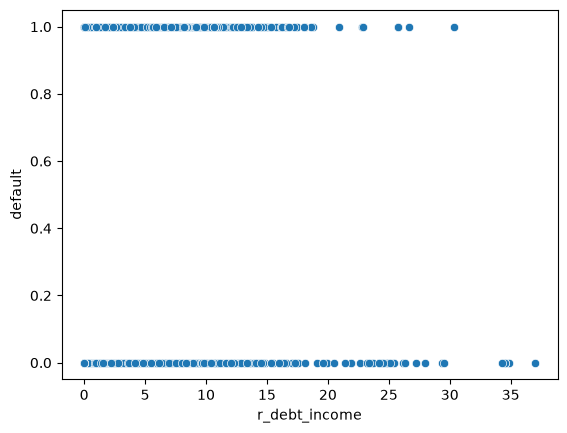

In [49]:
sns.scatterplot(x='r_debt_income', y='default', data=df)
plt.show()

In [ ]:
plt.hist(df['credit_score'], bins=10, color='blue', alpha=0.7)
plt.show()

In [57]:
count = 0
name = []
for col in df:
    if col.startswith('cat') != 1:
        name.append(col)

print(name)

['debt', 'r_savings_income', 'r_debt_income', 'r_debt_savings', 't_clothing_12', 't_clothing_6', 'r_clothing', 'r_clothing_income', 'r_clothing_savings', 'r_clothing_debt', 't_education_12', 't_education_6', 'r_education', 'r_education_income', 'r_education_savings', 'r_education_debt', 't_entertainment_12', 't_entertainment_6', 'r_entertainment', 'r_entertainment_income', 'r_entertainment_savings', 'r_entertainment_debt', 't_fines_12', 't_fines_6', 'r_fines', 'r_fines_income', 'r_fines_savings', 'r_fines_debt', 't_gambling_12', 't_gambling_6', 'r_gambling', 'r_gambling_income', 'r_gambling_savings', 'r_gambling_debt', 't_groceries_12', 't_groceries_6', 'r_groceries', 'r_groceries_income', 'r_groceries_savings', 'r_groceries_debt', 't_health_12', 't_health_6', 'r_health', 'r_health_income', 'r_health_savings', 'r_health_debt', 't_housing_12', 't_housing_6', 'r_housing', 'r_housing_income', 'r_housing_savings', 'r_housing_debt', 't_tax_12', 't_tax_6', 'r_tax', 'r_tax_income', 'r_tax_sav

In [101]:
#current_dir = Path(__file__).resolve().parent
file_path = "E:\\Credit_Risk_Scoring_repos\\data\\credit_score.csv"

  
df = pd.read_csv(file_path)
df.head(1)
df['CAT_GAMBLING'] = df['CAT_GAMBLING'].replace({'High':2,'Low':1,'No':0})

df.drop(df.columns[0], axis=1, inplace=True)  # Drop the first column if it's an index or ID    
print(f"Loaded raw dataset with shape: {df.shape} (80+ columns)")

target_col = 'DEFAULT' # Ensure this is 1 for Default/Bad, 0 for Good

# 2. AUTOMATED VARIABLE FILTERING
# This automatically drops columns that:
# - Have > 95% missing values
# - Have a single unique value (zero variance)
# - Have too many unique text categories (like names or unstructured comments)
print("\n--- Running Automated Variable Filtering ---")
#df_filtered = sc.var_filter(df, y='DEFAULT')

#df_filtered['DEFAULT'] = df['DEFAULT']
df_filtered = df
print(f"Dataset shape after quality filtering: {df_filtered.shape}")


# 3. Train-Test Split
data_split = sc.split_df(df_filtered, y='DEFAULT', ratio=0.7, seed=42)

train = data_split['train']
test = data_split['test']

print("Columns in train dataset:", train.columns.tolist())
    

Loaded raw dataset with shape: (1000, 86) (80+ columns)

--- Running Automated Variable Filtering ---
Dataset shape after quality filtering: (1000, 86)
Columns in train dataset: ['INCOME', 'SAVINGS', 'DEBT', 'R_SAVINGS_INCOME', 'R_DEBT_INCOME', 'R_DEBT_SAVINGS', 'T_CLOTHING_12', 'T_CLOTHING_6', 'R_CLOTHING', 'R_CLOTHING_INCOME', 'R_CLOTHING_SAVINGS', 'R_CLOTHING_DEBT', 'T_EDUCATION_12', 'T_EDUCATION_6', 'R_EDUCATION', 'R_EDUCATION_INCOME', 'R_EDUCATION_SAVINGS', 'R_EDUCATION_DEBT', 'T_ENTERTAINMENT_12', 'T_ENTERTAINMENT_6', 'R_ENTERTAINMENT', 'R_ENTERTAINMENT_INCOME', 'R_ENTERTAINMENT_SAVINGS', 'R_ENTERTAINMENT_DEBT', 'T_FINES_12', 'T_FINES_6', 'R_FINES', 'R_FINES_INCOME', 'R_FINES_SAVINGS', 'R_FINES_DEBT', 'T_GAMBLING_12', 'T_GAMBLING_6', 'R_GAMBLING', 'R_GAMBLING_INCOME', 'R_GAMBLING_SAVINGS', 'R_GAMBLING_DEBT', 'T_GROCERIES_12', 'T_GROCERIES_6', 'R_GROCERIES', 'R_GROCERIES_INCOME', 'R_GROCERIES_SAVINGS', 'R_GROCERIES_DEBT', 'T_HEALTH_12', 'T_HEALTH_6', 'R_HEALTH', 'R_HEALTH_INCOME',

In [105]:
print("1. In raw df:", 'DEFAULT' in df.columns)

# 2. Check right after variable filtering
df_filtered = sc.var_filter(df, y='DEFAULT')
print("2. In df_filtered:", 'DEFAULT' in df_filtered.columns)

# 3. Check after splitting
data_split = sc.split_df(df_filtered, y='DEFAULT', ratio=0.7, seed=42)
train = data_split['train']
print("3. In train set:", 'DEFAULT' in train.columns)

1. In raw df: True
[INFO] filtering variables ...
Variable filtering on 1000 rows and 86 columns in 00:03:02 
11 variables are removed
2. In df_filtered: True
3. In train set: False


In [108]:
train, test = train_test_split(
    df_filtered, 
    test_size=0.3,          # 30% for test, 70% for train
    random_state=42,        # Ensures reproducibility
    stratify=df_filtered['DEFAULT'] # Keeps default ratio balanced
)

# 2. Verify it worked instantly
print("Is target in train now?", target_col in train.columns)
print("Train shape:", train.shape)

Is target in train now? True
Train shape: (700, 75)


In [157]:
# 4. Optimal Binning & Information Value (IV) Calculation for remaining columns
df1 = df[["INCOME", "SAVINGS", 'DEFAULT']].copy()

# 2. Clean and force them into pure numeric types (handles strings with symbols, commas, or NaNs)
df1["INCOME"] = pd.to_numeric(df1["INCOME"], errors='coerce')
df1["SAVINGS"] = pd.to_numeric(df1["SAVINGS"], errors='coerce')
df1["DEFAULT"] = pd.to_numeric(df1["DEFAULT"], errors='coerce')

# 3. Drop any resulting rows with missing values that couldn't be parsed
df1 = df1.dropna()

print("\n--- Calculating Binning & Information Values (IV) ---")
bins = sc.woebin(df1, y='DEFAULT')
df1 = pd.DataFrame(df, columns=["INCOME", "SAVINGS",'DEFAULT'])
print("\n--- Calculating Binning & Information Values (IV) ---")
bins = sc.woebin(df1, y='DEFAULT')

#print(bins)


--- Calculating Binning & Information Values (IV) ---
[INFO] creating woe binning ...


ValueError: invalid error value specified

In [131]:
bins = sc.woebin(train, y='DEFAULT', bins=bins)

[INFO] creating woe binning ...


ValueError: invalid error value specified

In [124]:

    # Optional: If you want to drop variables with very low predictive power (IV < 0.02)
    # scorecardpy's woe_iv dataframe lets you inspect IVs, but sc.woebin handles most automatically.
    
    # 5. Convert data into Weight of Evidence (WoE) values
    train_woe = sc.woebin_ply(train, bins)
    test_woe = sc.woebin_ply(test, bins)

    # 6. Build the Logistic Regression Credit Scorecard
    print("\n--- Training Logistic Regression Scorecard on Filtered Features ---")
    print(bins)
    card = sc.scorecard(bins, train, y=target_col, points0=600, pdo=50)

    # 7. Generate Scores
    train_score = sc.scorecard_ply(train, card, points0=600, pdo=50)
    test_score = sc.scorecard_ply(test, card, points0=600, pdo=50)

    print("\n--- Sample Customer Credit Scores ---")
    print(test_score.head())

    # 8. Evaluate Model Performance
    sc.perf_eva(train[target_col], train_score, title="Train Set Performance")

[INFO] converting into woe values ...


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [158]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import xgboost as xgb

In [159]:
target_col = 'DEFAULT'
X = df_filtered.drop(columns=[target_col])
y = df_filtered[target_col]

# Handle categorical variables if any exist (XGBoost can handle numeric/categorical natively, 
# or you can use pd.get_dummies / one-hot encoding)
X = pd.get_dummies(X, drop_first=True)

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [160]:
# 3. Train the XGBoost Model
print("Training XGBoost Classifier...")
model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    eval_metric='logloss',
    random_state=42
)
model.fit(X_train, y_train)

# Evaluate model performance
y_pred_proba = model.predict_proba(X_test)[:, 1] # Probability of default (p)
auc = roc_auc_score(y_test, y_pred_proba)
print(f"Model ROC-AUC Score: {auc:.4f}")

# 4. Convert Probability of Default (p) into a Traditional Credit Score
# Formula parameters (standard banking convention)
# Target Score: 600 at Odds of 50:1 (Good:Bad) with a PDO (Points to Double Odds) of 50
base_score = 600
base_odds = 50.0
pdo = 50.0

factor = pdo / np.log(2)
offset = base_score - factor * np.log(base_odds)

# Avoid division by zero or log(0)
epsilon = 1e-6
p_clipped = np.clip(y_pred_proba, epsilon, 1 - epsilon)

# Calculate log-odds and final credit score
# Note: p is probability of default. Odds of default = p / (1 - p)
odds_default = p_clipped / (1 - p_clipped)
scores = offset - factor * np.log(odds_default)

# 5. Create final results DataFrame
results_df = pd.DataFrame({
    'Probability_of_Default': y_pred_proba,
    'Credit_Score': np.round(scores).astype(int)
})

print("\n--- Sample Scored Applicants (XGBoost) ---")
print(results_df.head(10))

Training XGBoost Classifier...
Model ROC-AUC Score: 0.6853

--- Sample Scored Applicants (XGBoost) ---
   Probability_of_Default  Credit_Score
0                0.712240           252
1                0.209830           413
2                0.168182           433
3                0.199524           418
4                0.504974           316
5                0.807797           214
6                0.246372           398
7                0.484010           322
8                0.612230           285
9                0.176816           429


In [166]:
import sys
from pathlib import Path

# Get the current working directory (project root)
root_dir = Path.cwd()

# Add to Python path if it's not already there
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

# Now your import will work seamlessly
from src.feature import clean_raw_data, engineer_features, preprocess_features
print("Successfully imported from src.feature!")

ModuleNotFoundError: No module named 'src'